In [ ]:
# 1. IMPORTS AND LIBRARIES
# Data Handling and Numerical Computing
import os
import numpy as np
import pandas as pd

# Visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Google Drive Integration
from google.colab import drive
import zipfile

# Machine Learning and Deep Learning
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv2D, MaxPooling2D, Flatten, Dense, Dropout
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, StandardScaler

# Image Processing
import cv2
import albumentations as A

In [ ]:
# 2. GOOGLE DRIVE INTEGRATION
def mount_google_drive():
    """
    Mount Google Drive and prepare dataset

    Returns:
    str: Path to the dataset
    """
    # Mount Google Drive
    drive.mount('/content/drive')

    # Path to dataset in Google Drive
    dataset_path = '/content/drive/MyDrive/Dataset - manual'

    # Optional: Unzip dataset if it's a zip file
    zip_path = '/content/drive/MyDrive/Dataset-manual.zip'
    if os.path.exists(zip_path):
        with zipfile.ZipFile(zip_path, 'r') as zip_ref:
            zip_ref.extractall('/content/drive/MyDrive/')

    return dataset_path

In [ ]:
# 3. DATA LOADING
def load_dataset(dataset_path, img_size=(224, 224)):
    """
    Load and preprocess images from the dataset

    Args:
    dataset_path (str): Path to the dataset directory
    img_size (tuple): Target image size for processing

    Returns:
    tuple: Images, labels, days to expiry
    """
    # Define categories
    fruits = ['apple', 'banana', 'orange', 'papaya', 'custard apple', 'guava']
    vegetables = ['cabbage', 'okra', 'cauliflower', 'spinach', 'fenugreek', 'brinjal']

    # Containers for data
    images = []
    labels = []
    days_to_expiry = []

    # Iterate through dataset
    for item_folder in os.listdir(dataset_path):
        item_path = os.path.join(dataset_path, item_folder)

        if os.path.isdir(item_path):
            # Determine category
            category = 'fruit' if item_folder.lower() in fruits else 'vegetable'

            # Sort images chronologically
            images_in_folder = sorted(
                [f for f in os.listdir(item_path) if f.lower().endswith(('.jpg', '.png', '.jpeg'))],
                key=lambda x: int(x.split('day')[-1].split('.')[0])
            )

            for i, img_file in enumerate(images_in_folder):
                img_full_path = os.path.join(item_path, img_file)

                try:
                    # Read and preprocess image
                    img = cv2.imread(img_full_path)
                    img = cv2.resize(img, img_size)
                    img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

                    images.append(img)
                    labels.append(category)

                    # Extract day number
                    day_number = int(img_file.split('day')[-1].split('.')[0])
                    days_to_expiry.append(day_number)

                except Exception as e:
                    print(f"Error processing {img_full_path}: {e}")

    return (
        np.array(images),
        np.array(labels),
        np.array(days_to_expiry)
    )

In [ ]:
# 4. DATA AUGMENTATION
def augment_data(images, labels, days_to_expiry):
    """
    Perform advanced image augmentation

    Args:
    images (np.array): Original images
    labels (np.array): Image labels
    days_to_expiry (np.array): Days to expiry for each image

    Returns:
    tuple: Augmented images, labels, days to expiry
    """
    # Augmentation configuration
    augmentations = A.Compose([
        A.RandomRotate90(p=0.5),
        A.Flip(p=0.5),
        A.ShiftScaleRotate(shift_limit=0.1, scale_limit=0.1, rotate_limit=45, p=0.5),
        A.RandomBrightnessContrast(p=0.3),
        A.GaussNoise(p=0.2),
        A.Blur(blur_limit=3, p=0.2),
        A.HueSaturationValue(p=0.3)
    ])

    augmented_images = []
    augmented_labels = []
    augmented_days = []

    # Augment each image
    for img, label, days in zip(images, labels, days_to_expiry):
        # Original image
        augmented_images.append(img)
        augmented_labels.append(label)
        augmented_days.append(days)

        # Generate 3 augmented versions
        for _ in range(3):
            augmented = augmentations(image=img)['image']
            augmented_images.append(augmented)
            augmented_labels.append(label)
            augmented_days.append(days)

    return (
        np.array(augmented_images),
        np.array(augmented_labels),
        np.array(augmented_days)
    )

In [ ]:
# 5. DATA PREPROCESSING
def preprocess_data(images, labels, days_to_expiry):
    """
    Preprocess data for model training

    Args:
    images (np.array): Images
    labels (np.array): Image labels
    days_to_expiry (np.array): Days to expiry

    Returns:
    tuple: Preprocessed data
    """
    # Normalize images
    images_normalized = images.astype('float32') / 255.0

    # Encode categorical labels
    label_encoder = LabelEncoder()
    labels_encoded = label_encoder.fit_transform(labels)

    return images_normalized, labels_encoded, days_to_expiry, label_encoder

In [ ]:
# 6. SPLITTING DATA
def split_data(images, labels, days_to_expiry, test_size=0.2):
    """
    Split data into training and testing sets

    Args:
    images (np.array): Normalized images
    labels (np.array): Encoded labels
    days_to_expiry (np.array): Days to expiry
    test_size (float): Proportion of data to use for testing

    Returns:
    tuple: Training and testing data splits
    """
    X_train, X_test, y_train, y_test, days_train, days_test = train_test_split(
        images, labels, days_to_expiry,
        test_size=test_size,
        random_state=42
    )

    return X_train, X_test, y_train, y_test, days_train, days_test

In [ ]:
# 7. MODEL CREATION
def create_shelf_life_model(input_shape):
    """
    Create CNN model for shelf life prediction

    Args:
    input_shape (tuple): Shape of input images

    Returns:
    tf.keras.Model: Compiled model
    """
    model = Sequential([
        # Convolutional layers
        Conv2D(32, (3, 3), activation='relu', input_shape=input_shape),
        MaxPooling2D((2, 2)),
        Conv2D(64, (3, 3), activation='relu'),
        MaxPooling2D((2, 2)),
        Conv2D(128, (3, 3), activation='relu'),
        MaxPooling2D((2, 2)),

        # Flatten and dense layers
        Flatten(),
        Dense(256, activation='relu'),
        Dropout(0.5),
        Dense(128, activation='relu'),

        # Regression output
        Dense(1, activation='linear')
    ])

    # Compile the model
    model.compile(
        optimizer=Adam(learning_rate=0.001),
        loss='mean_absolute_error',
        metrics=['mae']
    )

    return model

In [ ]:
# 8. MODEL TRAINING
def train_model(model, X_train, X_test, days_train, days_test, batch_size=32):
    """
    Train the shelf life prediction model

    Args:
    model (tf.keras.Model): Compiled model
    X_train, X_test: Training and testing images
    days_train, days_test: Training and testing days to expiry
    batch_size (int): Number of samples per gradient update

    Returns:
    History object from model training
    """
    # Callbacks
    early_stopping = EarlyStopping(
        monitor='val_loss',
        patience=10,
        restore_best_weights=True
    )

    reduce_lr = ReduceLROnPlateau(
        monitor='val_loss',
        factor=0.2,
        patience=5,
        min_lr=0.00001
    )

    # Train the model
    history = model.fit(
        X_train, days_train,
        validation_data=(X_test, days_test),
        epochs=100,
        batch_size=batch_size,
        callbacks=[early_stopping, reduce_lr]
    )

    return history


In [ ]:
# 9. MODEL EVALUATION
def evaluate_model(model, X_test, days_test):
    """
    Evaluate model performance

    Args:
    model (tf.keras.Model): Trained model
    X_test: Test images
    days_test: Actual days to expiry

    Returns:
    tuple: Performance metrics
    """
    # Predict and calculate metrics
    predictions = model.predict(X_test).flatten()
    mae = np.mean(np.abs(predictions - days_test))
    mse = np.mean((predictions - days_test)**2)
    rmse = np.sqrt(mse)

    # Visualization
    plt.figure(figsize=(10, 6))
    plt.scatter(days_test, predictions)
    plt.plot([days_test.min(), days_test.max()], [days_test.min(), days_test.max()], 'r--', lw=2)
    plt.xlabel('Actual Days')
    plt.ylabel('Predicted Days')
    plt.title('Shelf Life Prediction: Actual vs Predicted')
    plt.show()

    # Print metrics
    print("\nModel Performance Metrics:")
    print(f"Mean Absolute Error: {mae:.2f} days")
    print(f"Root Mean Squared Error: {rmse:.2f} days")

    return mae, rmse

In [ ]:
# 10. SHELF LIFE PREDICTION
def predict_shelf_life(model, new_image, img_size=(224, 224)):
    """
    Predict shelf life for a new image

    Args:
    model (tf.keras.Model): Trained model
    new_image (np.array): Input image
    img_size (tuple): Target image size

    Returns:
    float: Predicted days to expiry
    """
    # Preprocess new image
    processed_image = cv2.resize(new_image, img_size)
    processed_image = cv2.cvtColor(processed_image, cv2.COLOR_BGR2RGB)
    processed_image = processed_image.astype('float32') / 255.0
    processed_image = np.expand_dims(processed_image, axis=0)

    # Predict remaining shelf life
    predicted_days = model.predict(processed_image)[0][0]

    return predicted_days

In [ ]:
# 11. MAIN EXECUTION
def main():
    # Mount Google Drive and get dataset path
    dataset_path = mount_google_drive()

    # 1. Load Dataset
    images, labels, days_to_expiry = load_dataset(dataset_path)

    # 2. Data Augmentation
    images_aug, labels_aug, days_aug = augment_data(images, labels, days_to_expiry)

    # 3. Preprocessing
    images_processed, labels_encoded, days_processed, label_encoder = preprocess_data(
        images_aug, labels_aug, days_aug
    )

    # 4. Split Data
    X_train, X_test, y_train, y_test, days_train, days_test = split_data(
        images_processed, labels_encoded, days_processed
    )

    # 5. Create Model
    model = create_shelf_life_model(input_shape=(*images_processed.shape[1:4],))

    # 6. Train Model
    training_history = train_model(model, X_train, X_test, days_train, days_test)

    # 7. Evaluate Model
    mae, rmse = evaluate_model(model, X_test, days_test)

    return model, label_encoder

Mounted at /content/drive


<ipython-input-4-d0dc39bbde27>:17: DeprecationWarning: Flip is deprecated. Consider using HorizontalFlip, VerticalFlip, RandomRotate90 or D4.
  A.Flip(p=0.5),
/usr/local/lib/python3.10/dist-packages/keras/src/layers/convolutional/base_conv.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Epoch 1/100
8/8 ━━━━━━━━━━━━━━━━━━━━ 34s 4s/step - loss: 5.5762 - mae: 5.5762 - val_loss: 2.1625 - val_mae: 2.1625 - learning_rate: 0.0010
Epoch 2/100
8/8 ━━━━━━━━━━━━━━━━━━━━ 40s 4s/step - loss: 2.5946 - mae: 2.5946 - val_loss: 2.2562 - val_mae: 2.2562 - learning_rate: 0.0010
Epoch 3/100
8/8 ━━━━━━━━━━━━━━━━━━━━ 41s 4s/step - loss: 2.3489 - mae: 2.3489 - val_loss: 1.9515 - val_mae: 1.9515 - learning_rate: 0.0010
Epoch 4/100
8/8 ━━━━━━━━━━━━━━━━━━━━ 41s 4s/step - loss: 2.1621 - mae: 2.1621 - val_loss: 1.9977 - val_mae: 1.9977 - learning_rate: 0.0010
Epoch 5/100
8/8 ━━━━━━━━━━━━━━━━━━━━ 40s 4s/step - loss: 2.2303 - mae: 2.2303 - val_loss: 1.8720 - val_mae: 1.8720 - learning_rate: 0.0010
Epoch 6/100
8/8 ━━━━━━━━━━━━━━━━━━━━ 52s 5s/step - loss: 2.1042 - mae: 2.1042 - val_loss: 1.8928 - val_mae: 1.8928 - learning_rate: 0.0010
Epoch 7/100
8/8 ━━━━━━━━━━━━━━━━━━━━ 32s 4s/step - loss: 2.1753 - mae: 2.1753 - val_loss: 2.1022 - val_mae: 2.1022 - learning_rate: 0.0010
Epoch 8/100
8/8 ━━━━━━━━━━━

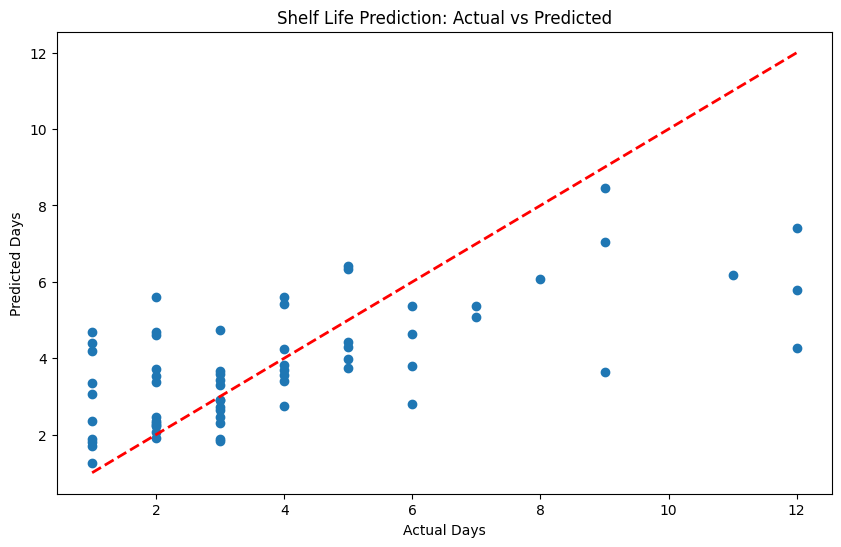


Model Performance Metrics:
Mean Absolute Error: 1.54 days
Root Mean Squared Error: 2.19 days


In [ ]:
# Run the main function
if __name__ == '__main__':
    trained_model, label_encoder = main()

In [ ]:
from google.colab import files
import cv2

# Step 1: Upload the image
uploaded = files.upload()

# Step 2: Read the uploaded image
image_path = list(uploaded.keys())[0]  # Get the uploaded file name
new_image = cv2.imread(image_path)

# Step 3: Predict the shelf life
predicted_days = predict_shelf_life(trained_model, new_image)
print(f"Predicted Shelf Life: {predicted_days:.2f} days")
